In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# Scikit-learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report,roc_auc_score


from imblearn.over_sampling import RandomOverSampler

# Random seed
np.random.seed(42)
RANDOM_STATE = 42


In [ ]:
# Generate synthetic student data with balanced risk classes
n_students = 10000

# Basic student info
student_id = np.arange(1, n_students+1)  # unique student ID
year = np.random.choice([1,2,3,4], n_students)  # academic year
gender = np.random.choice(['M','F'], n_students)  # gender
parent_education = np.random.choice(['none','highschool','bachelor','master'], n_students)  # parents' education
internet_access = np.random.choice([0,1], n_students)  # 0=no, 1=yes
distance_from_home_km = np.random.randint(1,50, n_students)  # distance from home to university (km)

# Academic features
ability = np.random.normal(75,10,n_students)  # student's ability score
midterm = np.random.randint(40,100,n_students)  # midterm exam score
practical = np.random.randint(40,100,n_students)  # practical score
writing = np.random.randint(40,100,n_students)  # writing score

# Behavioral / engagement features
dropped = np.random.choice([0,1], n_students, p=[0.85,0.15])  # whether student dropped any course
drop_amount = np.random.randint(0,3,n_students)  # number of dropped courses
study_hours = np.random.randint(0,30,n_students)  # weekly study hours
lms_sessions = np.random.randint(1,20,n_students)  # number of LMS sessions
avg_session_length = np.random.uniform(0.5,3.0,n_students)  # average session length (hours)
num_forum_posts = np.random.randint(0,15,n_students)  # number of forum posts

# Emotional features
motivation = np.random.randint(1,10,n_students)  # motivation level
stress_level = np.random.randint(1,10,n_students)  # stress level
forum_sentiment = np.random.uniform(-1,1,n_students)  # sentiment from forum posts (-1=negative, 1=positive)

# Risk target variable
# risk_score combines academic, behavioral, emotional features
risk_score = ( study_hours*0.3 + motivation*2 - stress_level*2 + lms_sessions*1.5 + np.random.normal(0,10,n_students))
# risk = 1 if in bottom 30% of risk_score, else 0
risk = (risk_score < np.percentile(risk_score,30)).astype(int)  # ~30% at risk

# Create DataFrame
data = pd.DataFrame({
    'student_id': student_id,
    'year': year,
    'gender': gender,
    'parent_education': parent_education,
    'internet_access': internet_access,
    'distance_from_home_km': distance_from_home_km,
    'ability': np.round(ability,2),
    'midterm': midterm,
    'practical': practical,
    'writing': writing,
    'dropped_flag': dropped,
    'drop_amount': drop_amount,
    'study_hours': study_hours,
    'lms_sessions': lms_sessions,
    'avg_session_length': np.round(avg_session_length,2),
    'num_forum_posts': num_forum_posts,
    'motivation': motivation,
    'stress_level': stress_level,
    'forum_sentiment': np.round(forum_sentiment,3),
    'risk': risk
})

# Check class distribution
print("Risk class distribution:", np.bincount(data['risk']))


Risk class distribution: [7000 3000]


In [ ]:
# Define features and encode categorical variables
academic_features = ['ability','midterm','practical','writing']
behavioral_features = ['study_hours','lms_sessions','avg_session_length','num_forum_posts','dropped_flag','drop_amount']
emotional_features = ['motivation','stress_level','forum_sentiment']
demographics = ['gender','parent_education','internet_access','distance_from_home_km']

all_features = academic_features + behavioral_features + emotional_features + demographics

# One-hot encode categorical variables
data_encoded = pd.get_dummies(data, columns=['gender','parent_education','internet_access'], drop_first=True)
X_academic = data_encoded[academic_features]
encoded_cats = [c for c in data_encoded.columns if 'gender_' in c or 'parent_education_' in c or 'internet_access_' in c]
X_all = data_encoded[academic_features + behavioral_features + emotional_features + ['distance_from_home_km'] + encoded_cats]

y = data_encoded['risk']

In [ ]:
# Split data and scale features

# Academic features: split into train and test sets, stratifying by risk to maintain class balance
X_train_a, X_test_a, y_train, y_test = train_test_split(
    X_academic, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# All features: split into train and test sets (same proportion), ignoring y output since y_train/y_test already defined
X_train_all, X_test_all, _, _ = train_test_split(
    X_all, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Scale features
scaler_a = StandardScaler()
X_train_a = scaler_a.fit_transform(X_train_a)
X_test_a = scaler_a.transform(X_test_a)

scaler_all = StandardScaler()
X_train_all = scaler_all.fit_transform(X_train_all)
X_test_all = scaler_all.transform(X_test_all)


In [ ]:
# Define a dictionary of ML models with their parameters
models = {
    # Logistic Regression: binary classifier, balanced classes, high max iterations
    'LogisticRegression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, class_weight='balanced'),

    # Decision Tree: limit depth to avoid overfitting, balanced classes
    'DecisionTree': DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE, class_weight='balanced'),

    # Random Forest: ensemble of 200 decision trees, balanced classes
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, class_weight='balanced'),

    # XGBoost: gradient boosting, 300 trees, learning rate 0.05, handle class imbalance
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05,
                             eval_metric='logloss', random_state=RANDOM_STATE, scale_pos_weight=2)
}


In [ ]:
#  Function to train and evaluate models
def evaluate_models(models, X_train, X_test, y_train, y_test):
    results = {}   # Dictionary to store performance metrics for each model

    for name, model in models.items():
        # Oversample to balance classes
        ros = RandomOverSampler(random_state=RANDOM_STATE)
        X_res, y_res = ros.fit_resample(X_train, y_train)

        #Train the model on the balanced data + Predict on test data
        model.fit(X_res, y_res)
        preds = model.predict(X_test)

        # Calculate performance metrics
        acc = accuracy_score(y_test, preds)
        roc = roc_auc_score(y_test, model.predict_proba(X_test)[:,1])

        print(f"\n{name} Accuracy: {acc:.3f}, ROC-AUC: {roc:.3f}")
        print(classification_report(y_test, preds, zero_division=0))
        # Save metrics to results dictionary
        results[name] = {'accuracy': acc, 'roc_auc': roc}
    return results


In [ ]:
# Train and evaluate models using ONLY Academic Features
print("Academic Features Only")
results_academic = evaluate_models(models, X_train_a, X_test_a, y_train, y_test)


Academic Features Only

LogisticRegression Accuracy: 0.487, ROC-AUC: 0.464
              precision    recall  f1-score   support

           0       0.68      0.50      0.58      1400
           1       0.28      0.45      0.34       600

    accuracy                           0.49      2000
   macro avg       0.48      0.48      0.46      2000
weighted avg       0.56      0.49      0.51      2000


DecisionTree Accuracy: 0.537, ROC-AUC: 0.475
              precision    recall  f1-score   support

           0       0.69      0.61      0.65      1400
           1       0.29      0.37      0.33       600

    accuracy                           0.54      2000
   macro avg       0.49      0.49      0.49      2000
weighted avg       0.57      0.54      0.55      2000


RandomForest Accuracy: 0.635, ROC-AUC: 0.503
              precision    recall  f1-score   support

           0       0.70      0.84      0.76      1400
           1       0.29      0.15      0.20       600

    accuracy   

In [ ]:
# Train and evaluate models using ALL available features
print("Academic + All Features")
results_all = evaluate_models(models, X_train_all, X_test_all, y_train, y_test)


Academic + All Features

LogisticRegression Accuracy: 0.776, ROC-AUC: 0.860
              precision    recall  f1-score   support

           0       0.90      0.77      0.83      1400
           1       0.60      0.79      0.68       600

    accuracy                           0.78      2000
   macro avg       0.75      0.78      0.75      2000
weighted avg       0.81      0.78      0.78      2000


DecisionTree Accuracy: 0.741, ROC-AUC: 0.829
              precision    recall  f1-score   support

           0       0.89      0.72      0.80      1400
           1       0.55      0.79      0.65       600

    accuracy                           0.74      2000
   macro avg       0.72      0.75      0.72      2000
weighted avg       0.79      0.74      0.75      2000


RandomForest Accuracy: 0.799, ROC-AUC: 0.847
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1400
           1       0.68      0.62      0.65       600

    accuracy  

In [ ]:
# Compare academic vs all features
compare = pd.DataFrame({'Academic Only': results_academic, 'All Features': results_all})
print(compare)


                                                        Academic Only  \
LogisticRegression  {'accuracy': 0.487, 'roc_auc': 0.4642333333333...   
DecisionTree        {'accuracy': 0.5375, 'roc_auc': 0.474689880952...   
RandomForest        {'accuracy': 0.635, 'roc_auc': 0.5029059523809...   
XGBoost             {'accuracy': 0.3915, 'roc_auc': 0.507202380952...   

                                                         All Features  
LogisticRegression  {'accuracy': 0.776, 'roc_auc': 0.8598940476190...  
DecisionTree                {'accuracy': 0.7405, 'roc_auc': 0.828725}  
RandomForest        {'accuracy': 0.799, 'roc_auc': 0.8469130952380...  
XGBoost             {'accuracy': 0.7435, 'roc_auc': 0.840205952380...  


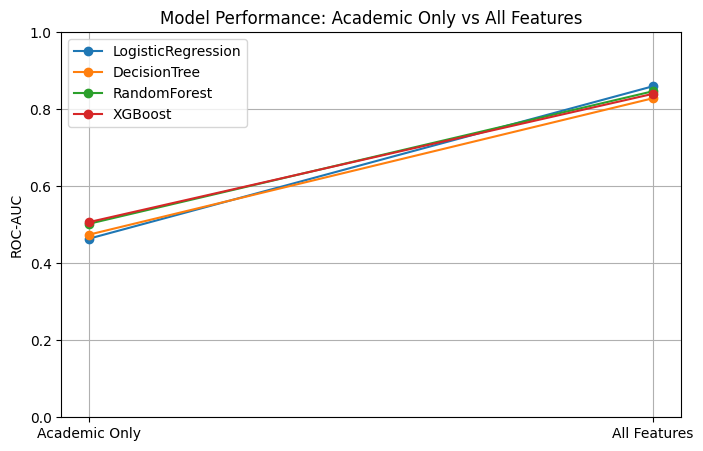

In [ ]:
# Plot Academic Only vs All Features (line plot)
plt.figure(figsize=(8,5))

for model in results_academic.keys():
    # ROC-AUC for Academic Only
    roc_a = results_academic[model]['roc_auc']
    # ROC-AUC for All Features
    roc_all = results_all[model]['roc_auc']

    # Plot line with two points (Academic vs All)
    plt.plot([0,1], [roc_a, roc_all], marker='o', label=model)

plt.xticks([0,1], ['Academic Only', 'All Features'])
plt.ylabel('ROC-AUC')
plt.title('Model Performance: Academic Only vs All Features')
plt.ylim(0,1)
plt.grid(True)
plt.legend()
plt.show()


In [ ]:
# Train models on different dataset sizes
dataset_sizes = [500, 2000, 5000, 10000, 20000]  # 20000 will be capped at dataset size
size_results_train = []

for size in dataset_sizes:
    # Ensure n does not exceed dataset length
    n = min(size, len(data_encoded))

    # Stratified sampling using groupby + frac
    frac = n / len(data_encoded)
    subset = data_encoded.groupby('risk', group_keys=False).apply(
        lambda x: x.sample(frac=frac, random_state=RANDOM_STATE)
    )

    X_sub = subset[X_all.columns]
    y_sub = subset['risk']

    # Stratified train-test split (20% test)
    X_train, X_test, y_train_sub, y_test_sub = train_test_split(
        X_sub, y_sub, test_size=0.2, random_state=RANDOM_STATE, stratify=y_sub
    )

    # Feature scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    for name, model in models.items():
        # Oversample minority class to balance
        ros = RandomOverSampler(random_state=RANDOM_STATE)
        X_res, y_res = ros.fit_resample(X_train_scaled, y_train_sub)

        # Train model
        model.fit(X_res, y_res)
        preds = model.predict(X_test_scaled)
        acc = accuracy_score(y_test_sub, preds)
        roc = roc_auc_score(y_test_sub, model.predict_proba(X_test_scaled)[:,1])

        # Append results
        size_results_train.append({
            'requested_size': size,  # original requested size
            'used_size': n,          # actual size used (capped)
            'model': name,
            'accuracy': acc,
            'roc_auc': roc
        })

        print(f"Requested size: {size}, Using: {n}, Model: {name}, Accuracy: {acc:.3f}, ROC-AUC: {roc:.3f}")

# Save results to DataFrame
results_df_train = pd.DataFrame(size_results_train)


Requested size: 500, Using: 500, Model: LogisticRegression, Accuracy: 0.790, ROC-AUC: 0.818
Requested size: 500, Using: 500, Model: DecisionTree, Accuracy: 0.730, ROC-AUC: 0.789


/tmp/ipython-input-684014672.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  subset = data_encoded.groupby('risk', group_keys=False).apply(


Requested size: 500, Using: 500, Model: RandomForest, Accuracy: 0.740, ROC-AUC: 0.803
Requested size: 500, Using: 500, Model: XGBoost, Accuracy: 0.770, ROC-AUC: 0.805
Requested size: 2000, Using: 2000, Model: LogisticRegression, Accuracy: 0.815, ROC-AUC: 0.875
Requested size: 2000, Using: 2000, Model: DecisionTree, Accuracy: 0.715, ROC-AUC: 0.777


/tmp/ipython-input-684014672.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  subset = data_encoded.groupby('risk', group_keys=False).apply(


Requested size: 2000, Using: 2000, Model: RandomForest, Accuracy: 0.785, ROC-AUC: 0.858
Requested size: 2000, Using: 2000, Model: XGBoost, Accuracy: 0.770, ROC-AUC: 0.844
Requested size: 5000, Using: 5000, Model: LogisticRegression, Accuracy: 0.759, ROC-AUC: 0.854
Requested size: 5000, Using: 5000, Model: DecisionTree, Accuracy: 0.742, ROC-AUC: 0.807


...

Requested size: 5000, Using: 5000, Model: RandomForest, Accuracy: 0.775, ROC-AUC: 0.835
Requested size: 5000, Using: 5000, Model: XGBoost, Accuracy: 0.752, ROC-AUC: 0.824
Requested size: 10000, Using: 10000, Model: LogisticRegression, Accuracy: 0.783, ROC-AUC: 0.866
Requested size: 10000, Using: 10000, Model: DecisionTree, Accuracy: 0.774, ROC-AUC: 0.832


/tmp/ipython-input-684014672.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  subset = data_encoded.groupby('risk', group_keys=False).apply(


Requested size: 10000, Using: 10000, Model: RandomForest, Accuracy: 0.795, ROC-AUC: 0.852
Requested size: 10000, Using: 10000, Model: XGBoost, Accuracy: 0.760, ROC-AUC: 0.848
Requested size: 20000, Using: 10000, Model: LogisticRegression, Accuracy: 0.783, ROC-AUC: 0.866
Requested size: 20000, Using: 10000, Model: DecisionTree, Accuracy: 0.774, ROC-AUC: 0.832


/tmp/ipython-input-684014672.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  subset = data_encoded.groupby('risk', group_keys=False).apply(


Requested size: 20000, Using: 10000, Model: RandomForest, Accuracy: 0.795, ROC-AUC: 0.852
Requested size: 20000, Using: 10000, Model: XGBoost, Accuracy: 0.760, ROC-AUC: 0.848


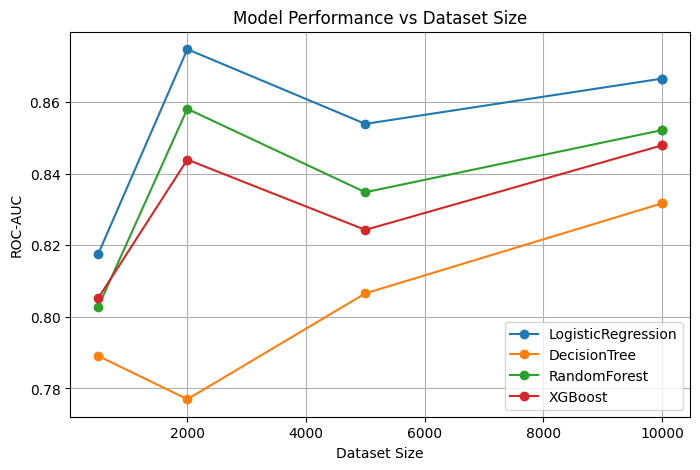

In [ ]:
# Plot ROC-AUC vs dataset size
plt.figure(figsize=(8,5))
for m in results_df_train['model'].unique():
    d = results_df_train[results_df_train['model'] == m]
    plt.plot(d['used_size'], d['roc_auc'], marker='o', label=m)  # use used_size
plt.xlabel('Dataset Size')
plt.ylabel('ROC-AUC')
plt.title('Model Performance vs Dataset Size')
plt.legend()
plt.grid(True)
plt.show()

